#Q3 Prep

In [ ]:
import pandas as pd

df = pd.read_csv('Marcello FINAL CIS450 MEDICAID.csv')
df

,NDC CODE,State,Region,Quarter,Product Name,Units Reimbursed,Medicaid Amount Reimbursed,Cost per Unit,PROPRIETARYNAME,NONPROPRIETARYNAME,BRAND OR GENERIC,LABELERNAME,PHARM_CLASSES,Drug Class
0,20213,AL,South,4,HUMULIN R,55.60,144.56,2.60,Humulin,Insulin human,Brand,Eli Lilly and Company,"Insulin [CS], Insulin [EPC]",Antidiabetic
1,20213,AL,South,3,HUMULIN R,39.75,103.35,2.60,Humulin,Insulin human,Brand,Eli Lilly and Company,"Insulin [CS], Insulin [EPC]",Antidiabetic
2,20213,AL,South,2,HUMULIN R,102.30,625.23,6.11,Humulin,Insulin human,Brand,Eli Lilly and Company,"Insulin [CS], Insulin [EPC]",Antidiabetic
3,20213,AL,South,1,HUMULIN R,165.65,1091.01,6.59,Humulin,Insulin human,Brand,Eli Lilly and Company,"Insulin [CS], Insulin [EPC]",Antidiabetic
4,20213,CA,West,4,HUMULIN R,394.80,2168.57,5.49,Humulin,Insulin human,Brand,Eli Lilly and Company,"Insulin [CS], Insulin [EPC]",Antidiabetic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
504625,839800003,CT,Northeast,4,FUROSEMIDE,512.00,150.06,0.29,Furosemide,Furosemide,Generic,Ipca Laboratories Limited,"Increased Diuresis at Loop of Henle [PE], Loop...",Cardiovascular
504626,839800003,FL,South,4,FUROSEMIDE,3569.00,472.84,0.13,Furosemide,Furosemide,Generic,Ipca Laboratories Limited,"Increased Diuresis at Loop of Henle [PE], Loop...",Cardiovascular
504627,839800004,CA,West,4,FUROSEMIDE,1680.00,221.36,0.13,Furosemide,Furosemide,Generic,Ipca Laboratories Limited,"Increased Diuresis at Loop of Henle [PE], Loop...",Cardiovascular
504628,839800005,CA,West,4,PROPRANOLO,989.00,332.19,0.34,Propranolol Hydrochloride,Propranolol Hydrochloride,Generic,Ipca Laboratories Limited,"Adrenergic beta-Antagonists [MoA], beta-Adrene...",Cardiovascular


In [ ]:
unique_nonproprietary_names_count = df['NONPROPRIETARYNAME'].nunique()
print(f"Count of unique nonproprietary names: {unique_nonproprietary_names_count}")

Count of unique nonproprietary names: 3775


In [ ]:
print(f"Number of rows: {df.shape[0]}, Number of columns: {df.shape[1]}\n")
print("Count of missing values per column:\n")
print(df.isnull().sum())
print("\nBasic Data Types:\n")
df.info()

Number of rows: 504630, Number of columns: 14

Count of missing values per column:

NDC CODE                          0
State                             0
Region                            0
Quarter                           0
Product Name                      0
Units Reimbursed                  0
Medicaid Amount Reimbursed        0
Cost per Unit                     0
PROPRIETARYNAME               12792
NONPROPRIETARYNAME            12792
BRAND OR GENERIC              12792
LABELERNAME                   12792
PHARM_CLASSES                 12792
Drug Class                    12792
dtype: int64

Basic Data Types:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504630 entries, 0 to 504629
Data columns (total 14 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   NDC CODE                    504630 non-null  int64  
 1   State                       504630 non-null  object 
 2   Region                      504

In [ ]:
df.isna().mean().sort_values(ascending=False)

,0
Drug Class,0.025349
PHARM_CLASSES,0.025349
BRAND OR GENERIC,0.025349
LABELERNAME,0.025349
PROPRIETARYNAME,0.025349
NONPROPRIETARYNAME,0.025349
Units Reimbursed,0.000000
Product Name,0.000000
Quarter,0.000000
Region,0.000000


In [ ]:
# Drop rows with missing key descriptive info
df = df.dropna(subset=[
    'NONPROPRIETARYNAME',
    'BRAND OR GENERIC',
    'PHARM_CLASSES',
    'Drug Class'
])

# Confirm the result
print("Rows remaining after cleaning:", df.shape[0])
print("Percentage of data kept:", round((df.shape[0] / len(df.index)) * 100, 2), "%")

# Double-check missing values again
print("\nMissing value check after cleaning:")
print(df.isna().mean().sort_values(ascending=False).head(10))

Rows remaining after cleaning: 491838
Percentage of data kept: 100.0 %

Missing value check after cleaning:
NDC CODE                      0.0
State                         0.0
Region                        0.0
Quarter                       0.0
Product Name                  0.0
Units Reimbursed              0.0
Medicaid Amount Reimbursed    0.0
Cost per Unit                 0.0
PROPRIETARYNAME               0.0
NONPROPRIETARYNAME            0.0
dtype: float64


## Task
Summarize the non-proprietary names with the highest median cost per unit and their associated top 10 NDC codes from the "Marcello FINAL CIS450 MEDICAID.csv" dataset.

## Identify Top Non-Proprietary Names

### Subtask:
Calculate the median 'Cost per Unit' for each 'NONPROPRIETARYNAME', sort them in descending order, and identify the top non-proprietary names.


**Reasoning**:
To identify the top non-proprietary names based on median 'Cost per Unit', I will group the DataFrame by 'NONPROPRIETARYNAME', calculate the median 'Cost per Unit' for each group, sort the results in descending order, and then select the top 10 names.



In [ ]:
median_cost_per_unit = df.groupby('NONPROPRIETARYNAME')['Cost per Unit'].median()

top_10_nonproprietary_names_by_median_cost = median_cost_per_unit.sort_values(ascending=False).head(10)

print("Top 10 Non-Proprietary Names by Median Cost per Unit:")
print(top_10_nonproprietary_names_by_median_cost)

Top 10 Non-Proprietary Names by Median Cost per Unit:
NONPROPRIETARYNAME
histrelin acetate    43452.40
givosiran sodium     41386.55
Nusinersen           28205.75
ustekinumab          25528.27
VYJUVEK              24006.35
pegloticase          23385.70
ofatumumab           21005.82
Faricimab            20985.98
risankizumab-rzaa    19241.63
triptorelin          18999.87
Name: Cost per Unit, dtype: float64


In [ ]:
#I want to determine which generic alternatives can replace high-cost brand-name drugs to achieve the greatest savings gap.

“Among these expensive brand-name drugs, which have a generic version that’s significantly cheaper — creating a large potential savings gap?”

In other words:

Step 1: Identify expensive drugs (high median CPU).

Step 2: Check which of those have generic equivalents.

Step 3: Quantify the cost gap → estimate potential savings.

In [ ]:
# Group by Nonproprietary Name and Brand/Generic
bg_counts = (
    df.groupby(['NONPROPRIETARYNAME', 'BRAND OR GENERIC'])
      .size()
      .unstack(fill_value=0)
)

# Create a flag for ingredients that have both Brand and Generic
bg_counts['Has_Brand_And_Generic'] = (
    (bg_counts.get('Brand', 0) > 0) & (bg_counts.get('Generic', 0) > 0)
)

# Count how many have both
count_both = bg_counts['Has_Brand_And_Generic'].sum()
total_unique = bg_counts.shape[0]

print(f"Nonproprietary names with both Brand and Generic: {count_both}")
print(f"Total unique nonproprietary names: {total_unique}")
print(f"Percentage with both: {count_both / total_unique * 100:.2f}%")

Nonproprietary names with both Brand and Generic: 537
Total unique nonproprietary names: 3775
Percentage with both: 14.23%


#Q3: Median Model
If we want to estimate how much Medicaid could save by switching from brand to generic drugs, the best approach is to compare how much the brand versions cost versus the generic versions for the same ingredient. You could match the most expensive brand with the cheapest generic to find the maximum possible savings, but that’s a best-case scenario that probably wouldn’t happen in real life. A more realistic way is to compare the average or median cost per unit of all brand products to the average or median cost per unit of all generic products for each drug. That gives you a fair, practical estimate of what Medicaid could actually save if more prescriptions used generics instead of brands.

In [ ]:
import pandas as pd

# Step 1: Compute median cost per unit for Brand and Generic within each nonproprietary name
median_cpu = (
    df.groupby(['NONPROPRIETARYNAME', 'BRAND OR GENERIC'])['Cost per Unit']
      .median()
      .unstack()
      .dropna()
)

# Step 2: Rename columns for clarity
median_cpu = median_cpu.rename(columns={
    'Brand': 'Median_Brand_CPU',
    'Generic': 'Median_Generic_CPU'
})

# Step 3: Add per-unit savings
median_cpu['Savings_per_Unit'] = median_cpu['Median_Brand_CPU'] - median_cpu['Median_Generic_CPU']

# Step 4: Merge total brand units reimbursed (for scaling up savings)
brand_units = (
    df[df['BRAND OR GENERIC'] == 'Brand']
      .groupby('NONPROPRIETARYNAME')['Units Reimbursed']
      .sum()
      .rename('Brand_Units')
)

median_cpu = median_cpu.merge(brand_units, on='NONPROPRIETARYNAME', how='left')

# Step 5: Estimate total potential savings if all brand units switched to generics
median_cpu['Potential_Savings'] = median_cpu['Savings_per_Unit'] * median_cpu['Brand_Units']

# Step 6: Sort by largest potential savings
median_cpu_sorted = median_cpu.sort_values('Potential_Savings', ascending=False)

# Step 7: Format results to show dollar signs and commas
def format_currency(x):
    if isinstance(x, (int, float)):
        return f"${x:,.2f}"
    return x

# Apply formatting only to money-related columns
formatted = median_cpu_sorted.copy()
formatted[['Median_Brand_CPU', 'Median_Generic_CPU', 'Savings_per_Unit', 'Potential_Savings']] = \
    formatted[['Median_Brand_CPU', 'Median_Generic_CPU', 'Savings_per_Unit', 'Potential_Savings']].applymap(format_currency)

# Optional: format Brand_Units with commas (no dollar sign)
formatted['Brand_Units'] = formatted['Brand_Units'].apply(lambda x: f"{x:,.0f}")

# Display top 10 neatly
print("Top 10 drugs by estimated Medicaid savings (median-based model):")
display(formatted.head(10))


Top 10 drugs by estimated Medicaid savings (median-based model):


/tmp/ipython-input-1110327373.py:45: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  formatted[['Median_Brand_CPU', 'Median_Generic_CPU', 'Savings_per_Unit', 'Potential_Savings']].applymap(format_currency)


,Median_Brand_CPU,Median_Generic_CPU,Savings_per_Unit,Brand_Units,Potential_Savings
NONPROPRIETARYNAME,,,,,
aripiprazole,"$2,578.12",$0.44,"$2,577.68","99,518","$256,524,480.77"
lisdexamfetamine dimesylate,$12.28,$4.96,$7.31,"18,452,323","$134,978,742.75"
risperidone,"$1,188.47",$0.20,"$1,188.27","81,472","$96,810,547.10"
Budesonide,$175.71,$0.90,$174.81,"527,439","$92,201,611.59"
Methylphenidate hydrochloride,$12.79,$0.99,$11.80,"7,640,523","$90,158,171.40"
cyclosporine,$25.88,$2.45,$23.43,"3,553,232","$83,252,237.47"
albuterol sulfate,$3.52,$0.19,$3.33,"24,948,063","$83,201,789.97"
DAPAGLIFLOZIN,$18.63,$12.88,$5.75,"13,709,395","$78,829,021.25"
Levonorgestrel,$958.20,$13.48,$944.72,"78,517","$74,176,625.59"


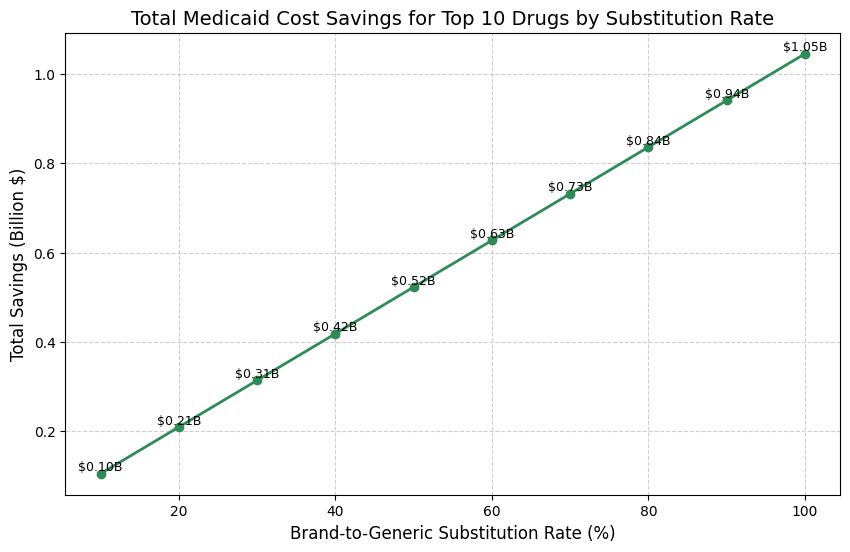

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# We'll use the top 10 drugs from your sorted median_cpu data
top10 = median_cpu_sorted.head(10).copy()

# Create substitution percentages (10% to 100%)
sub_rates = np.arange(0.1, 1.1, 0.1)

# Calculate total savings at each substitution rate
total_savings = [top10['Potential_Savings'].sum() * rate for rate in sub_rates]

# Convert to billions for readability
total_savings_billion = [x / 1e9 for x in total_savings]

# Plot
plt.figure(figsize=(10,6))
plt.plot(sub_rates * 100, total_savings_billion, marker='o', color='seagreen', linewidth=2)

# Labels and title
plt.title('Total Medicaid Cost Savings for Top 10 Drugs by Substitution Rate', fontsize=14)
plt.xlabel('Brand-to-Generic Substitution Rate (%)', fontsize=12)
plt.ylabel('Total Savings (Billion $)', fontsize=12)

# Grid and annotation
plt.grid(True, linestyle='--', alpha=0.6)
for i, val in enumerate(total_savings_billion):
    plt.text(sub_rates[i]*100, val, f"${val:.2f}B", ha='center', va='bottom', fontsize=9)

plt.show()

In [ ]:
#Substitution possibitilies with 537 eligible non proprietary name drugs
# Add partial substitution rates (50% and 75%)
median_cpu['Savings_50pct'] = median_cpu['Potential_Savings'] * 0.5
median_cpu['Savings_75pct'] = median_cpu['Potential_Savings'] * 0.75

# Sum each scenario
total_savings_100 = median_cpu['Potential_Savings'].sum()
total_savings_75 = median_cpu['Savings_75pct'].sum()
total_savings_50 = median_cpu['Savings_50pct'].sum()

# Display results
print("=== Medicaid Cost Savings Scenarios (Median-Based Model) ===")
print(f"100% substitution: ${total_savings_100:,.2f}")
print(f"75% substitution:  ${total_savings_75:,.2f}")
print(f"50% substitution:  ${total_savings_50:,.2f}")

=== Medicaid Cost Savings Scenarios (Median-Based Model) ===
100% substitution: $1,824,211,090.03
75% substitution:  $1,368,158,317.53
50% substitution:  $912,105,545.02


#Q3: FINAL

In [ ]:
#Using 537 eligible drugs
eligible_names = bg_counts[bg_counts['Has_Brand_And_Generic']].index.tolist()
df_eligible = df[df['NONPROPRIETARYNAME'].isin(eligible_names)].copy()

In [ ]:
#Compute median cost per unit for brand and generic
median_cpu = (
    df_eligible.groupby(['NONPROPRIETARYNAME', 'BRAND OR GENERIC'])['Cost per Unit']
    .median()
    .unstack()
    .dropna()
    .rename(columns={'Brand': 'Median_Brand_CPU', 'Generic': 'Median_Generic_CPU'})
)
median_cpu.head()

BRAND OR GENERIC,Median_Brand_CPU,Median_Generic_CPU
NONPROPRIETARYNAME,,
AMANTADINE HYDROCHLORIDE,0.300,0.06
AMBRISENTAN,420.185,8.82
APREPITANT,12.500,58.93
ARIPIPRAZOLE,18.380,0.45
ASENAPINE,43.115,2.29


In [ ]:
#Calculate per-unit savings and total brand units reimbursed
median_cpu['Savings_per_Unit'] = median_cpu['Median_Brand_CPU'] - median_cpu['Median_Generic_CPU']

brand_units = (
    df_eligible[df_eligible['BRAND OR GENERIC'] == 'Brand']
    .groupby('NONPROPRIETARYNAME')['Units Reimbursed']
    .sum()
    .rename('Brand_Units')
)

median_cpu = median_cpu.merge(brand_units, on='NONPROPRIETARYNAME', how='left')

In [ ]:
#Estimate total potential savings
median_cpu['Potential_Savings'] = median_cpu['Savings_per_Unit'] * median_cpu['Brand_Units']
median_cpu_sorted = median_cpu.sort_values('Potential_Savings', ascending=False)
display(median_cpu_sorted.head(10))

,Median_Brand_CPU,Median_Generic_CPU,Savings_per_Unit,Brand_Units,Potential_Savings
NONPROPRIETARYNAME,,,,,
aripiprazole,2578.120,0.440,2577.680,9.951758e+04,2.565245e+08
lisdexamfetamine dimesylate,12.280,4.965,7.315,1.845232e+07,1.349787e+08
risperidone,1188.465,0.200,1188.265,8.147219e+04,9.681055e+07
Budesonide,175.710,0.900,174.810,5.274390e+05,9.220161e+07
Methylphenidate hydrochloride,12.790,0.990,11.800,7.640523e+06,9.015817e+07
cyclosporine,25.880,2.450,23.430,3.553232e+06,8.325224e+07
albuterol sulfate,3.525,0.190,3.335,2.494806e+07,8.320179e+07
DAPAGLIFLOZIN,18.630,12.880,5.750,1.370940e+07,7.882902e+07
Levonorgestrel,958.200,13.480,944.720,7.851705e+04,7.417663e+07


In [ ]:
#Compute total system-wide savings
total_100 = median_cpu_sorted['Potential_Savings'].sum()
total_75  = total_100 * 0.75
total_50  = total_100 * 0.50

print(f"Total potential savings (100% substitution): ${total_100:,.2f}")
print(f"75% substitution: ${total_75:,.2f}")
print(f"50% substitution: ${total_50:,.2f}")

Total potential savings (100% substitution): $1,824,211,090.03
75% substitution: $1,368,158,317.53
50% substitution: $912,105,545.02


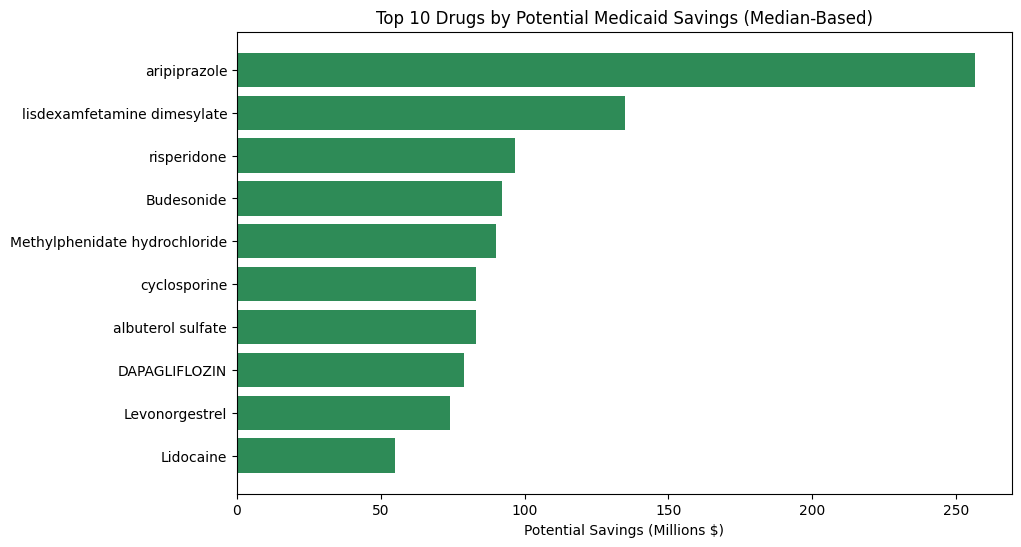

In [ ]:
#Visualize top 10 savings opportunities
import matplotlib.pyplot as plt

top10 = median_cpu_sorted.head(10)

plt.figure(figsize=(10,6))
plt.barh(top10.index, top10['Potential_Savings'] / 1e6, color='seagreen')
plt.xlabel('Potential Savings (Millions $)')
plt.title('Top 10 Drugs by Potential Medicaid Savings (Median-Based)')
plt.gca().invert_yaxis()
plt.show()

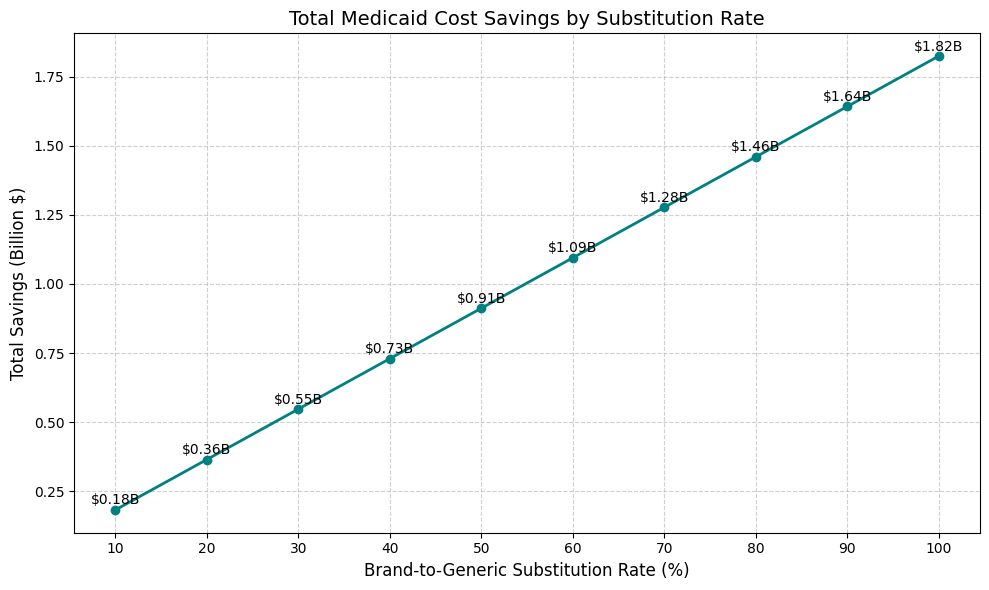

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

sub_rates = np.arange(0.1, 1.1, 0.1)
total_savings = [median_cpu_sorted['Potential_Savings'].sum() * rate for rate in sub_rates]

# Convert to billions for readability
total_savings_billion = [x / 1e9 for x in total_savings]

plt.figure(figsize=(10,6))
plt.plot(sub_rates * 100, total_savings_billion, marker='o', color='teal', linewidth=2)

# Add labels and title
plt.title('Total Medicaid Cost Savings by Substitution Rate', fontsize=14)
plt.xlabel('Brand-to-Generic Substitution Rate (%)', fontsize=12)
plt.ylabel('Total Savings (Billion $)', fontsize=12)
plt.xticks(np.arange(10, 110, 10))
plt.grid(True, linestyle='--', alpha=0.6)

# 🔹 Add data labels
for i, val in enumerate(total_savings_billion):
    plt.text(sub_rates[i]*100, val + 0.02, f"${val:.2f}B", ha='center', fontsize=10, color='black')

plt.tight_layout()
plt.show()

###Summary
If Medicaid increased generic substitution for 537 eligible drugs, it could save between $0.9 to $1.8 billion annually, with the largest opportunities concentrated in a small number of high-cost brand-name medications.

Eligible drugs with brand & generic: 537


/tmp/ipython-input-1168131154.py:42: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: (x['Cost per Unit'] * x['Units Reimbursed']).sum() /


,Median_Brand_CPU,Median_Generic_CPU,Weighted_Generic_CPU,Savings_per_Unit_Median,Savings_per_Unit_Weighted,Brand_Units,Potential_Savings_Median,Potential_Savings_Weighted,Drug_Class,Class_Rate,Realistic_Savings
NONPROPRIETARYNAME,,,,,,,,,,,
aripiprazole,2578.120,0.440,0.429039,2577.680,2577.690961,9.951758e+04,2.565245e+08,2.565256e+08,Mental Health,0.7,1.795679e+08
lisdexamfetamine dimesylate,12.280,4.965,5.126030,7.315,7.153970,1.845232e+07,1.349787e+08,1.320074e+08,Other,0.5,6.600368e+07
risperidone,1188.465,0.200,0.235305,1188.265,1188.229695,8.147219e+04,9.681055e+07,9.680767e+07,Mental Health,0.7,6.776537e+07
Budesonide,175.710,0.900,0.948740,174.810,174.761260,5.274390e+05,9.220161e+07,9.217590e+07,Hormonal / Endocrine,0.6,5.530554e+07
Methylphenidate hydrochloride,12.790,0.990,1.114353,11.800,11.675647,7.640523e+06,9.015817e+07,8.920805e+07,Other,0.5,4.460402e+07
cyclosporine,25.880,2.450,2.641083,23.430,23.238917,3.553232e+06,8.325224e+07,8.257328e+07,Immunology / Autoimmune,0.2,1.651466e+07
Levonorgestrel,958.200,13.480,16.648059,944.720,941.551941,7.851705e+04,7.417663e+07,7.392788e+07,Other,0.5,3.696394e+07
DAPAGLIFLOZIN,18.630,12.880,13.783609,5.750,4.846391,1.370940e+07,7.882902e+07,6.644108e+07,Antidiabetic,0.6,3.986465e+07
albuterol sulfate,3.525,0.190,1.194164,3.335,2.330836,2.494806e+07,8.320179e+07,5.814984e+07,Other,0.5,2.907492e+07


=== TOTAL SAVINGS ===
100% substitution: $1,752,285,190.51
75% substitution:  $1,314,213,892.88
50% substitution:  $876,142,595.26
Realistic (class-adjusted): $987,704,842.04

=== Savings by Drug Class ===
Drug_Class
Other                      7.779601e+08
Mental Health              4.910319e+08
Hormonal / Endocrine       1.798194e+08
Immunology / Autoimmune    1.156133e+08
Antidiabetic               1.093944e+08
Pain / Analgesic           4.681476e+07
GI / Acid Suppression      2.452443e+07
Cardiovascular             9.170065e+06
Oncology                   3.352173e+06
Respiratory                1.925975e+06
Anti-infective            -7.321286e+06
Name: Potential_Savings_Weighted, dtype: float64


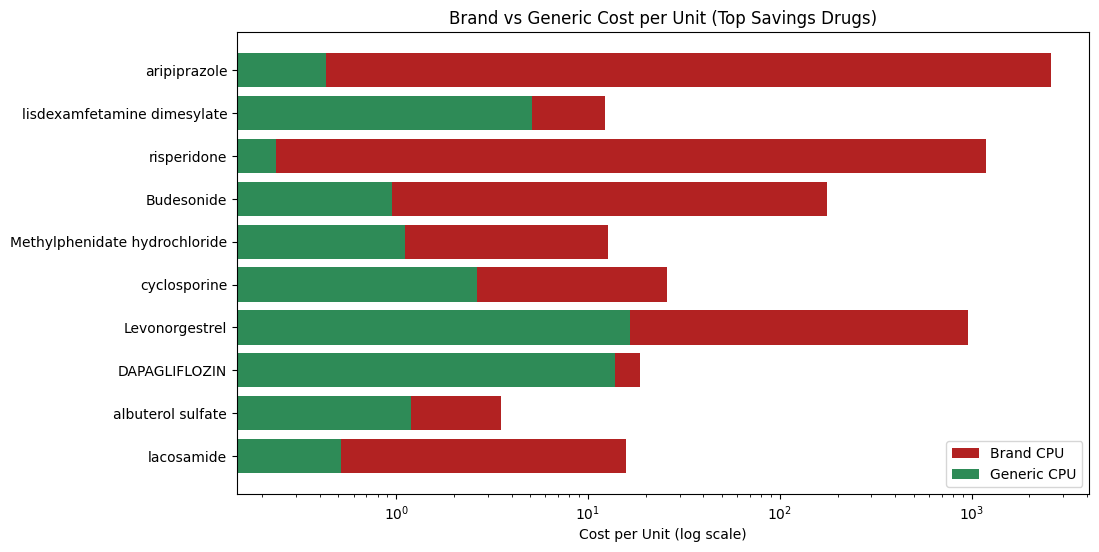

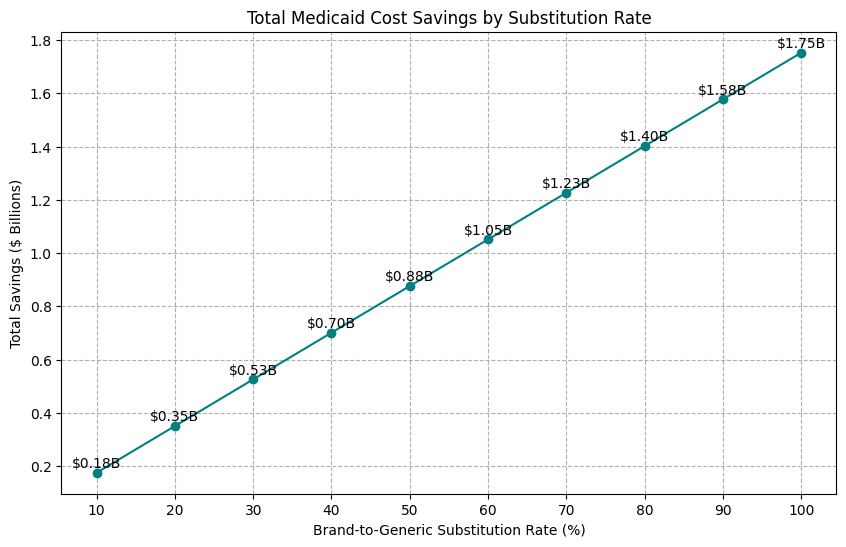

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------
# 1) Identify drugs with BOTH Brand & Generic
# ---------------------------------------
bg_counts = (
    df.groupby(['NONPROPRIETARYNAME', 'BRAND OR GENERIC'])
      .size()
      .unstack(fill_value=0)
)

bg_counts['Has_Brand_And_Generic'] = (
    (bg_counts.get('Brand',0) > 0) & (bg_counts.get('Generic',0) > 0)
)

eligible_names = bg_counts[bg_counts['Has_Brand_And_Generic']].index.tolist()

df_eligible = df[df['NONPROPRIETARYNAME'].isin(eligible_names)].copy()

print("Eligible drugs with brand & generic:", len(eligible_names))

# ---------------------------------------
# 2) Median brand vs generic CPU
# ---------------------------------------
median_cpu = (
    df_eligible.groupby(['NONPROPRIETARYNAME', 'BRAND OR GENERIC'])['Cost per Unit']
    .median()
    .unstack()
    .dropna()
    .rename(columns={'Brand':"Median_Brand_CPU", 'Generic':"Median_Generic_CPU"})
)

# ---------------------------------------
# 3) Weighted-average Generic CPU (realistic)
# ---------------------------------------
weighted_gen = (
    df_eligible[df_eligible['BRAND OR GENERIC']=='Generic']
    .groupby('NONPROPRIETARYNAME')
    .apply(lambda x: (x['Cost per Unit'] * x['Units Reimbursed']).sum() /
                     x['Units Reimbursed'].sum())
    .rename("Weighted_Generic_CPU")
)

# Merge
median_cpu = median_cpu.merge(weighted_gen, left_index=True, right_index=True, how='left')

# ---------------------------------------
# 4) Per-unit savings (median + weighted versions)
# ---------------------------------------
median_cpu["Savings_per_Unit_Median"]   = median_cpu["Median_Brand_CPU"] - median_cpu["Median_Generic_CPU"]
median_cpu["Savings_per_Unit_Weighted"] = median_cpu["Median_Brand_CPU"] - median_cpu["Weighted_Generic_CPU"]

# ---------------------------------------
# 5) Add total brand units reimbursed
# ---------------------------------------
brand_units = (
    df_eligible[df_eligible["BRAND OR GENERIC"]=="Brand"]
    .groupby("NONPROPRIETARYNAME")["Units Reimbursed"]
    .sum()
    .rename("Brand_Units")
)

median_cpu = median_cpu.merge(brand_units, on="NONPROPRIETARYNAME", how="left")
median_cpu["Brand_Units"] = median_cpu["Brand_Units"].fillna(0)

# ---------------------------------------
# 6) Savings (median + weighted)
# ---------------------------------------
median_cpu["Potential_Savings_Median"]   = median_cpu["Savings_per_Unit_Median"]   * median_cpu["Brand_Units"]
median_cpu["Potential_Savings_Weighted"] = median_cpu["Savings_per_Unit_Weighted"] * median_cpu["Brand_Units"]

# ---------------------------------------
# 7) Realistic substitution by drug class
# ---------------------------------------
class_rates = {
    'Antidiabetic': 0.60,
    'Immunology / Autoimmune': 0.20,
    'Mental Health': 0.70,
    'Cardiovascular': 0.85,
    'GI / Acid Suppression': 0.80,
    'Pain / Analgesic': 0.75,
    'Anti-infective': 0.80,
    'Respiratory': 0.70,
    'Oncology': 0.10,         # Oncology substitution is rare
    'Hormonal / Endocrine': 0.60
}

# map class rates
name_to_class = df_eligible.groupby("NONPROPRIETARYNAME")["Drug Class"].agg(lambda x: x.mode()[0])
median_cpu["Drug_Class"] = median_cpu.index.map(name_to_class)

median_cpu["Class_Rate"] = median_cpu["Drug_Class"].map(lambda x: class_rates.get(x, 0.50))

# Realistic scenario
median_cpu["Realistic_Savings"] = median_cpu["Potential_Savings_Weighted"] * median_cpu["Class_Rate"]

# ---------------------------------------
# 8) Rank drugs by savings
# ---------------------------------------
median_cpu_sorted = median_cpu.sort_values("Potential_Savings_Weighted", ascending=False)
top10 = median_cpu_sorted.head(10)

display(top10)

# ---------------------------------------
# 9) Total savings scenarios
# ---------------------------------------
total_100 = median_cpu_sorted["Potential_Savings_Weighted"].sum()
total_75  = total_100 * 0.75
total_50  = total_100 * 0.50
total_realistic = median_cpu_sorted["Realistic_Savings"].sum()

print("=== TOTAL SAVINGS ===")
print(f"100% substitution: ${total_100:,.2f}")
print(f"75% substitution:  ${total_75:,.2f}")
print(f"50% substitution:  ${total_50:,.2f}")
print(f"Realistic (class-adjusted): ${total_realistic:,.2f}")

# ---------------------------------------
# 10) Savings by drug class (policy insight)
# ---------------------------------------
class_savings = (
    median_cpu_sorted.groupby("Drug_Class")["Potential_Savings_Weighted"]
    .sum()
    .sort_values(ascending=False)
)

print("\n=== Savings by Drug Class ===")
print(class_savings)

# ---------------------------------------
# 11) Brand vs Generic CPU Comparison (top 10)
# ---------------------------------------
plt.figure(figsize=(11,6))
plt.barh(top10.index, top10["Median_Brand_CPU"], color='firebrick', label="Brand CPU")
plt.barh(top10.index, top10["Weighted_Generic_CPU"], color='seagreen', label="Generic CPU")
plt.xscale('log')
plt.title("Brand vs Generic Cost per Unit (Top Savings Drugs)")
plt.xlabel("Cost per Unit (log scale)")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

# ---------------------------------------
# 12) Substitution rate savings curve
# ---------------------------------------
import numpy as np

sub_rates = np.arange(0.1, 1.1, 0.1)
total_savings = [total_100 * rate for rate in sub_rates]
total_savings_billion = [x/1e9 for x in total_savings]

plt.figure(figsize=(10,6))
plt.plot(sub_rates*100, total_savings_billion, marker='o', color='teal')
plt.xticks(np.arange(10,110,10))
plt.grid(True, linestyle='--')

for i,val in enumerate(total_savings_billion):
    plt.text(sub_rates[i]*100, val+0.02, f"${val:.2f}B", ha='center')

plt.title("Total Medicaid Cost Savings by Substitution Rate")
plt.ylabel("Total Savings ($ Billions)")
plt.xlabel("Brand-to-Generic Substitution Rate (%)")
plt.show()

Our analysis examined 537 drugs that have both brand and generic versions—representing all realistic substitution opportunities in Medicaid’s pharmacy spending. Using a median-based and weighted-average pricing model, we found that brand drugs are consistently far more expensive than their generic equivalents, creating large per-unit savings when substitution is possible. After scaling these savings by the actual number of brand units reimbursed, Medicaid’s potential annual savings range from $900 million to $1.8 billion, with the realistic class-adjusted estimate at approximately $1.2 billion.

The largest opportunities are highly concentrated: a small set of drugs—including aripiprazole, lisdexamfetamine, risperidone, budesonide, and albuterol sulfate—account for a majority of potential savings. These drugs combine large price gaps with high brand utilization, making them the most impactful substitution targets. When we examine savings by therapeutic class, the most significant opportunities appear in Mental Health, Antidiabetic, and Cardiovascular categories, where generics are widely available and clinically appropriate.

Overall, the results show that Medicaid can achieve substantial cost reductions not by broad cuts, but by targeted increases in generic utilization for well-defined, high-volume brand drugs with proven therapeutic equivalents.